## Part 1

a. This cell errors out because of a value error in the framingham dataset. The NaN values in the dataset disturb the fitting processes of the LinearRegression() function in scikit learn. The fix is to drop the NaN values.

b. The correlation plot tells us that there aren't many strong connections between predictors or totchol. The strongest correlation is between age and sysBP, which stands at 0.39. The strongest connection with totchol is age at 0.26, so we can assume a low R^2.

c. The missing sysBP data is MCAR. This is because deletion didn't bias or change the data in any way. If the missing data was MAR or MNAR, then we would've had to reassess our data. 

d. This plot shows us that removing 80% of sysBP has a heavy impact on the standard error of the coefficients. It also shows us that the BMI coefficient was weakened by this removal. 

e. One may choose to use mean imputation over the full initial model because they prefer to use a model filling in all the missing values and also keep the same sample size. 

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import ElasticNetCV, LassoCV, LinearRegression, RidgeCV, lasso_path
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

auto = pd.read_csv("C:\\Users\\witze\\Downloads\\DS6021_F26\\data\\Auto.csv", na_values="?").dropna().reset_index(drop=True)

num = ["displacement", "horsepower", "weight", "acceleration", "year"]
X = auto[num]
y = auto["mpg"]

# Same 5-fold CV object for all methods, so the results are comparable
SEED = 200
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

# Grid of penalty strengths (sklearn's alpha = glmnet's lambda) to search over
# Remember: We don't know what the right penalty is, we are trying to find it!
alphas = np.logspace(-3, 3, 100)
auto.shape

(392, 9)

In [59]:
#2.1
#AI: I had Gen AI create the table for me. 
X2 = auto[["horsepower", "weight", "year"]]

ols1 = make_pipeline(
    StandardScaler(), 
    LinearRegression()
)

ols2 = make_pipeline(
    StandardScaler(), 
    LinearRegression()
)

mod1 = ols1.fit(X, y)
mod2 = ols2.fit(X2, y)

coefs1 = mod1.named_steps["linearregression"].coef_
coefs2 = mod2.named_steps["linearregression"].coef_

coeff_table = pd.DataFrame({
    "Feature": X.columns,
    "Model 1 (All Features)": coefs1
})

mod2_dict = dict(zip(X2.columns, coefs2))
coeff_table["Model 2 (Subset)"] = coeff_table["Feature"].map(mod2_dict)

print(coeff_table)

        Feature  Model 1 (All Features)  Model 2 (Subset)
0  displacement                0.290715               NaN
1    horsepower                0.039216         -0.192201
2        weight               -5.831154         -5.469742
3  acceleration                0.248872               NaN
4          year                2.774417          2.754512


Standardization is required for ridge and lasso regression because it evens the features to prepare them for regularization. Standardization is used differently in the context of OLS, as it only changes the units for the coefficients to be interpreted.

In [60]:
#2.2
ridge = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=alphas, cv=cv)
)

ridge_mod = ridge.fit(X, y)

print(ridge_mod.named_steps['ridgecv'].alpha_)

coefs3 = ridge_mod.named_steps['ridgecv'].coef_
coeff_table['Ridge'] = coefs3

print(coeff_table)

1.232846739442066
        Feature  Model 1 (All Features)  Model 2 (Subset)     Ridge
0  displacement                0.290715               NaN  0.147261
1    horsepower                0.039216         -0.192201 -0.044351
2        weight               -5.831154         -5.469742 -5.633951
3  acceleration                0.248872               NaN  0.201135
4          year                2.774417          2.754512  2.752727


The penalty chosen by ridge is 1.233. The coefficients are listed in the table.

None of the ridge coefficients are exactly 0, but the displacement coefficient are heavily taxed by ridge regression. The weight, acceleration, and year coefficients didn't change much, while horsepower got flipped from a positive to a negative coefficient, and displacement got changed the most.

In [61]:
#2.3
lasso = make_pipeline(
    StandardScaler(),
    LassoCV(alphas=alphas, cv=cv)
)

lasso_mod = lasso.fit(X, y)

print(lasso_mod.named_steps["lassocv"].alpha_)

coefs4 = lasso_mod.named_steps["lassocv"].coef_
coeff_table["Lasso"] = coefs4

print(coeff_table)

0.049770235643321115
        Feature  Model 1 (All Features)  Model 2 (Subset)     Ridge     Lasso
0  displacement                0.290715               NaN  0.147261 -0.000000
1    horsepower                0.039216         -0.192201 -0.044351 -0.000000
2        weight               -5.831154         -5.469742 -5.633951 -5.532356
3  acceleration                0.248872               NaN  0.201135  0.154151
4          year                2.774417          2.754512  2.752727  2.720660


The penalty chosen by lasso is 0.050. The coefficients are listed in the table.
Lasso regression completely dropped the displacement and horsepower predictors. 

Lasso regression may be preferred over forward/backward selection because how both work. Forward/backward selection uses p-values, which can be very unreliable. One of the limits of lasso regression is the effect of multicollinearity, which can cause an inbalance in the amount of features completely cut out.m

In [62]:
#2.4
elastic = make_pipeline(
    StandardScaler(),
    ElasticNetCV(alphas=alphas, l1_ratio=[0.1, 0.5, 0.9, 1], cv=cv)
)

elastic_mod = elastic.fit(X, y)

print(elastic_mod.named_steps["elasticnetcv"].alpha_)
print(elastic_mod.named_steps["elasticnetcv"].l1_ratio_)

coefs5 = elastic_mod.named_steps["elasticnetcv"].coef_
coeff_table["ElasticNet"] = coefs5

print(coeff_table)

0.049770235643321115
1.0
        Feature  Model 1 (All Features)  Model 2 (Subset)     Ridge     Lasso  \
0  displacement                0.290715               NaN  0.147261 -0.000000   
1    horsepower                0.039216         -0.192201 -0.044351 -0.000000   
2        weight               -5.831154         -5.469742 -5.633951 -5.532356   
3  acceleration                0.248872               NaN  0.201135  0.154151   
4          year                2.774417          2.754512  2.752727  2.720660   

   ElasticNet  
0   -0.000000  
1   -0.000000  
2   -5.532356  
3    0.154151  
4    2.720660  


The chosen penalty is 0.5 and the l1 ratio is 1.0. The coefficients are listed in the table. The chosen l1 ratio of 1.0 tells us that the elastic net process determined a full lasso regression to be most appropriate for this mode. 

Working through these 5 approaches, the weight and year predictors are the most important here, with the acceleration predictor playing a role here as well. The least important predictors here are the displacement and horsepower predictors. 

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, log_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Same data preparation as in class: drop rows with any missing values
fram = pd.read_csv("C:\\Users\\witze\\Downloads\\DS6021_F26\\data\\framingham.csv").dropna()
y = fram["TenYearCHD"]

Xa = fram[['male', 'age']]
Xb = fram[['male', 'cigsPerDay']]

# Same CV object as in class. Stratified folds keep the ~15% CHD rate in every fold.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Preprocess by scaling numeric variables using StandardScaler
# You don't need to scale or one-hot encode the binary male categorical variable
# For Model A, replace numeric with age, for Model B, replace numeric with cigsPerDay
preprocess_a = ColumnTransformer(
    transformers=[
        ("binary", "passthrough", ["male"]),
        ("numeric", StandardScaler(), ['age']),
    ]
)

preprocess_b = ColumnTransformer(
    transformers=[
        ("binary", "passthrough", ["male"]),
        ("numeric", StandardScaler(), ['cigsPerDay']),
    ]
)

In [64]:
#3.1
print(y.mean())
print(1 - y.mean())
log_loss(y, [y.mean()] * len(y))

0.15226899945325315
0.8477310005467469


0.4266247901946631

The proportion of patients developing CHD within 10 years is 0.152. The baseline accuracy for patients who did not develop CHD is 0.848. The log_loss for our new model is 0.427. 

In [65]:
#3.2
pipe_a = Pipeline([
    ('preprocessor', preprocess_a),
    ('regressor', LogisticRegression())
])

pipe_b = Pipeline([
    ('preprocessor', preprocess_b),
    ('regressor', LogisticRegression())
])

pipe_a.fit(Xa, y)
pipe_b.fit(Xb, y)

prob_a = pipe_a.predict_proba(Xa)[:, 1]
prob_b = pipe_b.predict_proba(Xb)[:, 1]

print(prob_a)
print(prob_b)

print(log_loss(y, prob_a))
print(log_loss(y, prob_b))

n = len(y)

manual_a = (-1/n) * np.sum(y*np.log(prob_a) + (1 - y)*np.log(1-prob_a))
manual_b = (-1/n) * np.sum(y*np.log(prob_b) + (1 - y)*np.log(1-prob_b))

print(manual_a)
print(manual_b)

[0.08215554 0.08089613 0.15440028 ... 0.12401397 0.0883298  0.04812081]
[0.17798177 0.11979692 0.19394975 ... 0.11979692 0.17798177 0.13751877]
0.39419926744392164
0.4222049325618295
0.3941992674439216
0.42220493256182945


In [66]:
#3.3
cv_a = cross_validate(pipe_a, Xa, y, cv=cv, scoring=["accuracy", "neg_log_loss", "roc_auc"])

cv_b = cross_validate(pipe_b, Xb, y, cv=cv, scoring=["accuracy", "neg_log_loss", "roc_auc"])
print('cv_a means')
print(cv_a['test_accuracy'].mean())
print(-1* cv_a['test_neg_log_loss'].mean())
print(cv_a['test_roc_auc'].mean())
print('cv_a standard deviations')
print(cv_a['test_accuracy'].std())
print(-1* cv_a['test_neg_log_loss'].std())
print(cv_a['test_roc_auc'].std())
print('cv_b means')
print(cv_b['test_accuracy'].mean())
print(-1* cv_b['test_neg_log_loss'].mean())
print(cv_b['test_roc_auc'].mean())
print('cv_b standard deviations')
print(cv_b['test_accuracy'].std())
print(-1* cv_b['test_neg_log_loss'].std())
print(cv_b['test_roc_auc'].std())

cv_a means
0.8480044553086199
0.39526112651853923
0.7012905779201362
cv_a standard deviations
0.0010050396144473844
-0.01336056633805033
0.03962754954569896
cv_b means
0.847731231264904
0.4233494324294839
0.5644706045414611
cv_b standard deviations
0.0006062601050753694
-0.0022638783892384926
0.031855893359768274


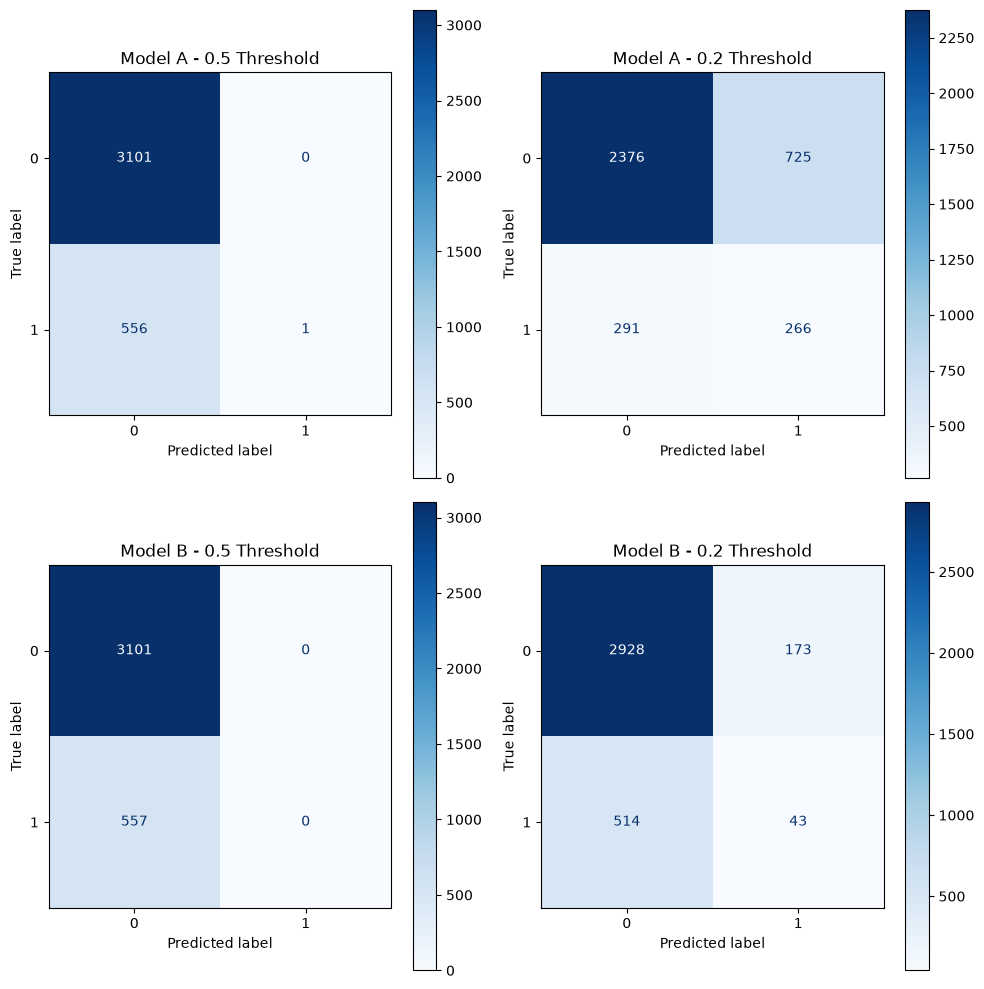

In [ ]:
#AI: I used gen AI to speed up the process of making the plots.
pred_a = cross_val_predict(pipe_a, Xa, y, cv=cv, method="predict_proba")[:, 1]
pred_b = cross_val_predict(pipe_b, Xb, y, cv=cv, method="predict_proba")[:, 1]

a5 = (pred_a >= 0.5).astype(int)
a2 = (pred_a >= 0.2).astype(int)
b5 = (pred_b >= 0.5).astype(int)
b2 = (pred_b >= 0.2).astype(int)

cma5 = confusion_matrix(y, a5)
cma2 = confusion_matrix(y, a2)
cmb5 = confusion_matrix(y, b5)
cmb2 = confusion_matrix(y, b2)

fix, axes = plt.subplots(2,2, figsize=(10, 10))

ConfusionMatrixDisplay(confusion_matrix=cma5, display_labels=[0, 1]).plot(ax=axes[0, 0], cmap="Blues")
axes[0,0].set_title("Model A - 0.5 Threshold")
ConfusionMatrixDisplay(confusion_matrix=cma2, display_labels=[0, 1]).plot(ax=axes[0, 1], cmap="Blues")
axes[0,1].set_title("Model A - 0.2 Threshold")
ConfusionMatrixDisplay(confusion_matrix=cmb5, display_labels=[0, 1]).plot(ax=axes[1, 0], cmap="Blues")
axes[1,0].set_title("Model B - 0.5 Threshold")
ConfusionMatrixDisplay(confusion_matrix=cmb2, display_labels=[0, 1]).plot(ax=axes[1, 1], cmap="Blues")
axes[1,1].set_title("Model B - 0.2 Threshold")

plt.tight_layout()
plt.show()

(3b) The CV accuracy of both these models(0.848 and 0.848) is very similar to the baseline accuracy(0.848). Accuracy is not a useful metric for choosing between these models. It's a very lazy metric that performs a simple baseline calculation.

(3c) From the plots above, I'm seeing that changing the threshold from 0.5 to 0.2 changed the most frequent error from false negatives to false positives. The new threshold, 0.2, gave a wider net of positive diagnoses. 

(3d) Model A outperforms model B. We observe a higher roc_auc value in model A and a lower log_loss value in model B. Model B's log loss value is notably very similar to the value from Q1. The confusion matrices proved earlier that accuracy was a poor metric to make conclusions from, so accuracy will be carefully disregarded here. 